(sec-6-2)=
# 6.2 Aliasing and Anti-Aliasing

Suppose an ECG recorder samples at 128 Hz while a 120 Hz interference component reaches its input. In the stored samples, that interference can appear as an 8 Hz oscillation. This is *aliasing*: different continuous-time signals can produce the same sample values.

I will show why this happens using a sinusoid and a few substitutions. Then we will compare the sampled waveforms and spectra in Python. The practical point is that anti-aliasing must happen before sampling, or before reducing the sampling rate; filtering afterward cannot uniquely recover the original frequencies.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-6-2-1)=
## 6.2.1 Aliasing in the Time Domain

Take a sinusoid $x(t) = \cos(2\pi f_0 t + \varphi)$ and sample it at $f_s = 1/T_s$. The samples are

$$
x[n] = \cos(2\pi f_0 n T_s + \varphi) = \cos\!\left(2\pi \frac{f_0}{f_s} n + \varphi\right).
$$

The ratio $f_0/f_s$ tells us how many cycles occur per sample. With $f_0=120$ Hz and $f_s=128$ Hz, this is $120/128=0.9375$ cycles per sample. For a zero-phase cosine, subtracting one full cycle at every integer index leaves the same sample values as $-0.0625$ cycles per sample. Because cosine is even, those values also match an $8$ Hz cosine. Other phases must be tracked as well; the important point is that the samples alone cannot distinguish these possibilities.

Now take a second sinusoid whose frequency differs from the first by a whole multiple of the sampling rate, $f_1 = f_0 + k f_s$ with $k$ an integer, and sample it in the same way.

**Step 1: write out its samples.**

$$
\cos\!\left(2\pi \frac{f_0 + k f_s}{f_s} n + \varphi\right) = \cos\!\left(2\pi \frac{f_0}{f_s} n + 2\pi k n + \varphi\right).
$$

**Step 2: remove the whole turns.** Since $k$ and $n$ are both integers, $2\pi k n$ is a whole number of turns, and the cosine has period $2\pi$. The extra term disappears:

(eq-6-6)=
\begin{equation*}
\cos\!\big(2\pi (f_0 + k f_s) n T_s + \varphi\big) = \cos(2\pi f_0 n T_s + \varphi) = x[n]. \tag{6.6}
\end{equation*}

The two sinusoids are different functions of continuous time, yet every one of their samples agrees. The sampler cannot tell them apart. The same argument with a negative frequency gives a second family of impostors. For $f_2 = k f_s - f_0$,

(eq-6-7)=
\begin{equation*}
\begin{aligned}
\cos\!\big(2\pi (k f_s - f_0) n T_s + \varphi\big) &= \cos\!\big(2\pi k n - 2\pi f_0 n T_s + \varphi\big) \\
&= \cos\!\big(-(2\pi f_0 n T_s - \varphi)\big) \\
&= \cos(2\pi f_0 n T_s - \varphi), 
\end{aligned} \tag{6.7}
\end{equation*}

where the second line drops the whole turns again and the third uses the fact that cosine is even. A sinusoid at $k f_s - f_0$ produces the samples of a sinusoid at $f_0$ with its phase reversed. Equations [(6.6)](#eq-6-6) and [(6.7)](#eq-6-7) together say that, as far as the samples are concerned, the frequencies $f_0$, $f_s \pm f_0$, $2f_s \pm f_0$, $\ldots$ are all the same frequency. Each of them is an **alias** of the others.

**Example 6.2.1.** A low-cost sensor samples at $f_s = 50$ Hz. Show that sinusoids at 10, 40 and 60 Hz, all with zero phase, give identical samples.

With $f_0 = 10$ Hz, the 60 Hz sinusoid is $f_0 + f_s$ (equation 9.6 with $k = 1$) and the 40 Hz sinusoid is $f_s - f_0$ (equation 9.7 with $k = 1$; the phase reversal does nothing because $\varphi = 0$). All three therefore produce the samples $\cos(2\pi\,10\,n/50) = \cos(0.4\pi n)$. Mains interference at 60 Hz, sampled at 50 Hz, looks exactly like a 10 Hz rhythm, which in an EEG would be read as alpha activity.

In [2]:
fs = 50.0
n = np.arange(11)
samples = {f: np.cos(2 * np.pi * f * n / fs) for f in (10.0, 40.0, 60.0)}
for f, x in samples.items():
    print(f"{f:4.0f} Hz: {np.round(x[:6], 4)}")
print("40 Hz equal to 10 Hz:", np.allclose(samples[40.0], samples[10.0]),
      "| 60 Hz equal to 10 Hz:", np.allclose(samples[60.0], samples[10.0]))

  10 Hz: [ 1.     0.309 -0.809 -0.809  0.309  1.   ]
  40 Hz: [ 1.     0.309 -0.809 -0.809  0.309  1.   ]
  60 Hz: [ 1.     0.309 -0.809 -0.809  0.309  1.   ]
40 Hz equal to 10 Hz: True | 60 Hz equal to 10 Hz: True


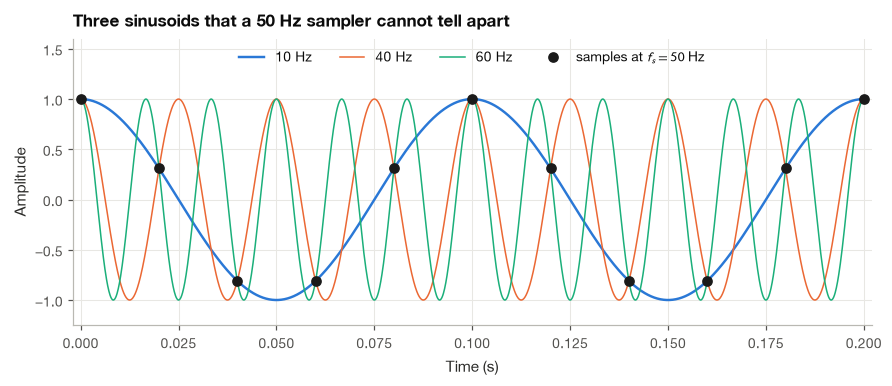

In [3]:
t = np.linspace(0, 0.2, 2000)
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, f in enumerate((10.0, 40.0, 60.0)):
    ax.plot(t, np.cos(2 * np.pi * f * t), color=C[k], lw=1.6 if f == 10 else 1.0, label=f"{f:.0f} Hz")
ax.plot(n / fs, samples[10.0], "o", color="0.1", ms=6, label="samples at $f_s = 50$ Hz")
ax.set(xlabel="Time (s)", ylabel="Amplitude", ylim=(-1.25, 1.6),
       title="Three sinusoids that a 50 Hz sampler cannot tell apart")
ax.legend(loc="upper center", ncol=4)
plt.show()

The 10 Hz curve is the "slowest" sinusoid that passes through the dots, and it is the one an ideal reconstruction filter would return. The faster curves pass through the same dots by completing one or more extra cycles between samples. A sampled signal does not know how many cycles were skipped.

(sec-6-2-2)=
## 6.2.2 The Folding Formula

Equations [(6.6)](#eq-6-6) and [(6.7)](#eq-6-7) tell us which frequencies collide. We usually want the reverse: given a component at frequency $f$, at what frequency will it *appear* after sampling? By convention the answer is the alias that lies in the range $0 \le f_a \le f_s/2$, because that is the band an ideal reconstruction filter keeps and the band a spectrum of the sampled data displays.

**Step 1: shift by a multiple of $f_s$.** By [(6.6)](#eq-6-6) we may subtract any multiple of $f_s$ without changing the samples. Choosing the multiple nearest to $f$, $k = \operatorname{round}(f/f_s)$, brings the frequency into the interval $[-f_s/2, f_s/2]$.

**Step 2: discard the sign.** For a real sinusoid a negative frequency is the same as the positive one with the phase reversed, as [(6.7)](#eq-6-7) showed. Taking the absolute value gives the **apparent frequency**

(eq-6-8)=
\begin{equation*}
f_a = \left| f - f_s \operatorname{round}\!\left(\frac{f}{f_s}\right) \right|. \tag{6.8}
\end{equation*}

Plotted against $f$, equation [(6.8)](#eq-6-8) is a zigzag. As $f$ rises from 0 to $f_s/2$ the apparent frequency follows it. Between $f_s/2$ and $f_s$ it runs back down to zero, between $f_s$ and $3f_s/2$ it rises again, and so on. It is as if the frequency axis were a strip of paper folded like an accordion, with creases at every multiple of $f_s/2$; everything printed on the strip ends up stacked on the first panel, $[0, f_s/2]$. This is why $f_s/2$ is called the **folding frequency**.

For the wearable patch of the introduction, $f_s = 128$ Hz, the mains harmonics land as follows. The formula is easy to implement, and we check it against the definition by confirming that each harmonic and its predicted alias give identical samples (with the phase reversed when the harmonic falls on a descending branch of the zigzag).

In [4]:
def apparent_frequency(f, fs):
    """Frequency at which a component at f appears after sampling at fs, equation (9.8)."""
    return np.abs(f - fs * np.round(f / fs))


fs_patch = 128.0
n = np.arange(256)
phi = 0.7                                       # arbitrary phase, rad
for f in (60.0, 120.0, 180.0, 240.0, 300.0):
    fa = apparent_frequency(f, fs_patch)
    x_true = np.cos(2 * np.pi * f * n / fs_patch + phi)
    folded = (f - fs_patch * np.round(f / fs_patch)) < 0      # landed on a descending branch
    x_alias = np.cos(2 * np.pi * fa * n / fs_patch + (-phi if folded else phi))
    print(f"{f:5.0f} Hz appears at {fa:5.1f} Hz   samples identical: {np.allclose(x_true, x_alias)}")

   60 Hz appears at  60.0 Hz   samples identical: True
  120 Hz appears at   8.0 Hz   samples identical: True
  180 Hz appears at  52.0 Hz   samples identical: True
  240 Hz appears at  16.0 Hz   samples identical: True
  300 Hz appears at  44.0 Hz   samples identical: True


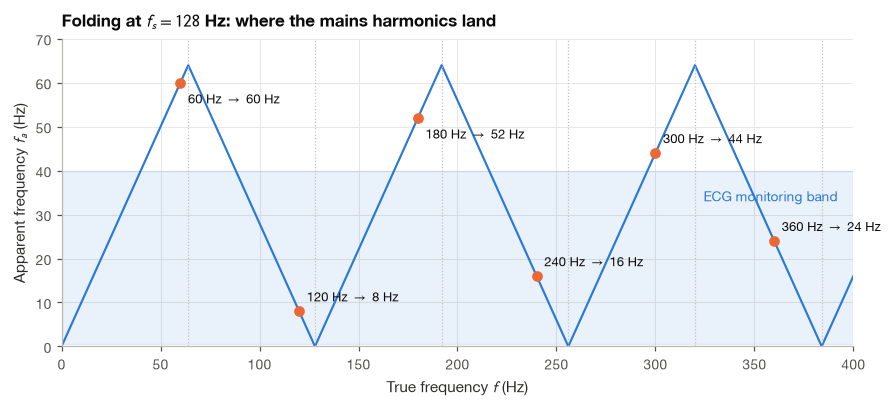

In [5]:
f_axis = np.linspace(0, 400, 4001)
harmonics = np.array([60.0, 120.0, 180.0, 240.0, 300.0, 360.0])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhspan(0.5, 40, color=C[0], alpha=0.10)
ax.text(392, 36, "ECG monitoring band", ha="right", va="top", fontsize=9, color=C[0])
ax.plot(f_axis, apparent_frequency(f_axis, fs_patch), color=C[0])
for m in range(1, 7):
    ax.axvline(m * fs_patch / 2, color="0.75", lw=0.8, ls=":")
ax.plot(harmonics, apparent_frequency(harmonics, fs_patch), "o", color=C[1], ms=6, zorder=3)
for f in harmonics:
    fa = apparent_frequency(f, fs_patch)
    ax.annotate(f"{f:.0f} Hz $\\rightarrow$ {fa:.0f} Hz", (f, fa), textcoords="offset points",
                xytext=(5, 6 if fa < 50 else -14), fontsize=8.5)
ax.set(xlabel="True frequency $f$ (Hz)", ylabel="Apparent frequency $f_a$ (Hz)", xlim=(0, 400), ylim=(0, 70),
       title="Folding at $f_s = 128$ Hz: where the mains harmonics land")
plt.show()

The 60 Hz fundamental lies just below the folding frequency of 64 Hz and stays where it is. Its harmonics do not: 120 Hz folds to 8 Hz, 240 Hz to 16 Hz and 360 Hz to 24 Hz, all inside the band where an ECG monitor looks for QRS complexes, while 180 and 300 Hz land at 52 and 44 Hz. A notch filter at 60 Hz removes only the fundamental. The dotted vertical lines are the creases of the accordion, at multiples of 64 Hz.

(sec-6-2-3)=
## 6.2.3 Aliasing in a Real Recording: Needle EMG

Sinusoids make the mechanism clear, but real signals have continuous spectra, and then aliasing is less visible: folded power simply piles on top of the genuine power and distorts the shape of the spectrum. A clear example is the needle electromyogram, whose motor unit potentials contain energy up to several kilohertz. I use the PhysioNet EMG example from a patient with myopathy {cite:p}`goldberger2000`, recorded with a concentric needle in the tibialis anterior at 4 kHz. Myopathic motor unit potentials are short and polyphasic, so this recording has more high-frequency content than the healthy one, which makes the effect easy to see.

Suppose we want to store this signal at 500 Hz, for example to analyze it alongside an ECG sampled at that rate. There are two ways to reduce the rate by a factor of $M = 8$: keep every eighth sample (naive downsampling), or low-pass filter first and then keep every eighth sample. We compare the two.

### Step 1: Load the recording and look at it

In [6]:
rec = wfdb.rdrecord("../data/emgdb/emg_myopathy")
emg = rec.p_signal[:, 0]
fs_emg = rec.fs
print(f"{emg.size} samples at {fs_emg} Hz = {emg.size / fs_emg:.1f} s, range {emg.min():.2f} to {emg.max():.2f} mV")

110337 samples at 4000 Hz = 27.6 s, range -0.67 to 0.78 mV


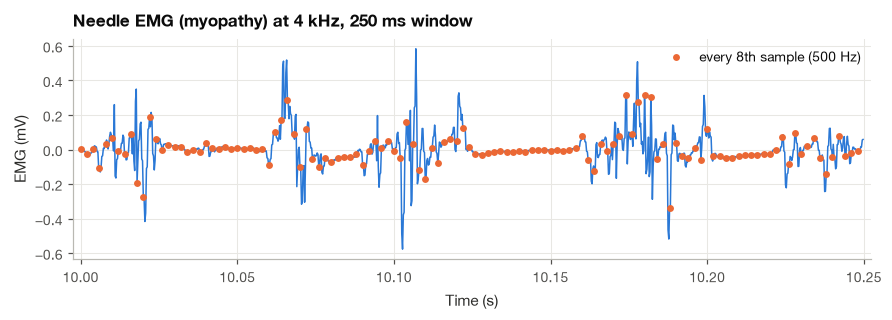

In [7]:
t_emg = np.arange(emg.size) / fs_emg
win = (t_emg >= 10.0) & (t_emg < 10.25)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(t_emg[win], emg[win], color=C[0], lw=1)
ax.plot(t_emg[win][::8], emg[win][::8], "o", color=C[1], ms=3.5, label="every 8th sample (500 Hz)")
ax.set(xlabel="Time (s)", ylabel="EMG (mV)", title="Needle EMG (myopathy) at 4 kHz, 250 ms window")
ax.legend(loc="upper right")
plt.show()

The orange dots are what naive downsampling keeps. They miss most of the sharp turns of the motor unit potentials, and nothing tells us what happened between them.

### Step 2: Estimate the spectrum at the original rate

We again use Welch's method as a black-box spectrum estimator ([Section 7.3](../ch12_spectral_estimation/index.md)), with 1 s segments so that the frequency resolution is 1 Hz.

In [8]:
M = 8
fs_low = fs_emg / M                       # 500 Hz
f_hi, P_hi = signal.welch(emg, fs_emg, nperseg=int(fs_emg))
above = f_hi > fs_low / 2
print(f"New Nyquist frequency: {fs_low / 2:.0f} Hz")
print(f"Fraction of EMG power above {fs_low / 2:.0f} Hz: {P_hi[above].sum() / P_hi.sum():.1%}")

New Nyquist frequency: 250 Hz
Fraction of EMG power above 250 Hz: 47.8%


Almost half of the power lies above the new Nyquist frequency. All of it will fold into the 0–250 Hz band unless we remove it first.

### Step 3: Downsample naively and predict the result with the folding formula

Folding is a deterministic rearrangement of the frequency axis, so we can predict the spectrum of the naively downsampled signal from the original spectrum alone: move every frequency bin to its apparent frequency with equation [(6.8)](#eq-6-8) and add up the power that lands in each place. Comparing the prediction with the spectrum actually measured from `emg[::M]` is a good test of the theory.

In [9]:
emg_naive = emg[::M]
f_lo, P_naive = signal.welch(emg_naive, fs_low, nperseg=int(fs_low))

P_pred = np.zeros_like(f_lo)
fa_bins = np.round(apparent_frequency(f_hi, fs_low)).astype(int)     # 1 Hz bins on both grids
np.add.at(P_pred, fa_bins, P_hi)

inner = (f_lo > 5) & (f_lo < 245)
ratio = P_pred[inner] / P_naive[inner]
print(f"Predicted / measured naive PSD: median {np.median(ratio):.3f}, "
      f"10th-90th percentile {np.percentile(ratio, 10):.2f}-{np.percentile(ratio, 90):.2f}")

Predicted / measured naive PSD: median 1.006, 10th-90th percentile 0.88-1.17


The prediction matches the measured spectrum to within the statistical scatter of the estimates, with a median ratio very close to 1. The naive spectrum really is the original spectrum folded like an accordion.

### Step 4: Filter first, then downsample

`scipy.signal.decimate` low-pass filters the signal with an FIR filter whose cutoff is the new Nyquist frequency and then keeps every $M$-th sample. [Section 6.2.5](#sec-6-2-5) below opens this function up and rebuilds it from scratch.

In [10]:
emg_dec = signal.decimate(emg, M, ftype="fir", zero_phase=True)
_, P_dec = signal.welch(emg_dec, fs_low, nperseg=int(fs_low))
P_true = P_hi[: f_lo.size]                # the original spectrum on 0-250 Hz is the target
print(f"Samples after downsampling: {emg_naive.size} (naive), {emg_dec.size} (filtered)")

Samples after downsampling: 13793 (naive), 13793 (filtered)


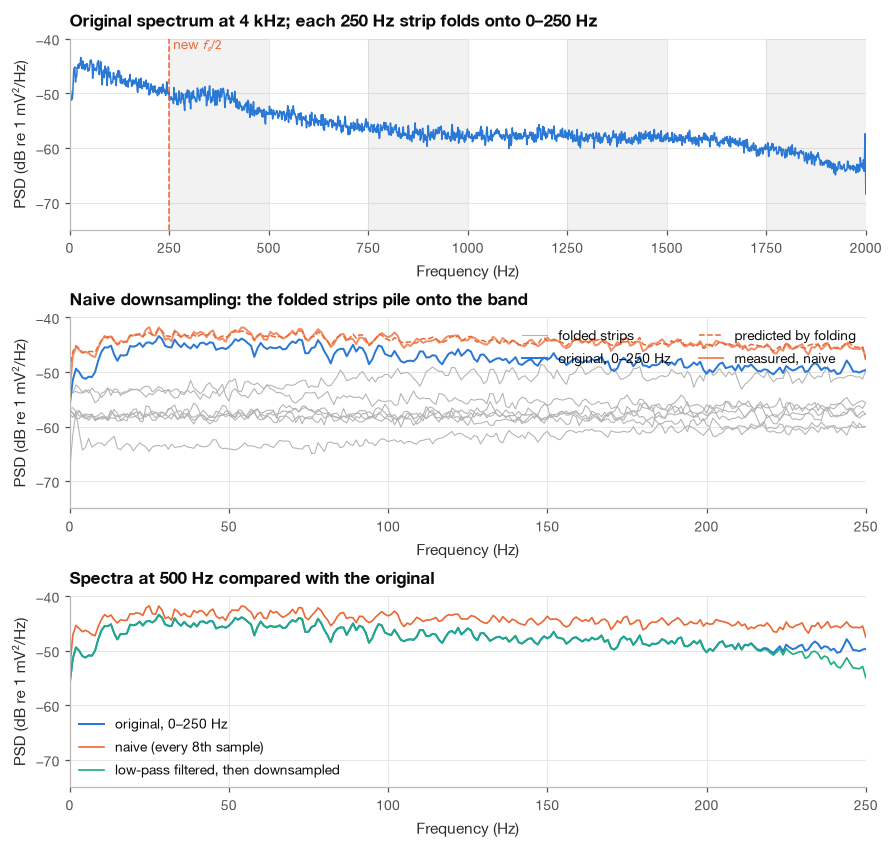

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(8, 7.6))
ax = axes[0]
ax.plot(f_hi, 10 * np.log10(P_hi), color=C[0], lw=1)
for m in range(1, 8):
    if m % 2:
        ax.axvspan(m * 250, (m + 1) * 250, color="0.6", alpha=0.12, lw=0)
ax.axvline(250, color=C[1], ls="--", lw=1)
ax.text(260, -42, "new $f_s/2$", color=C[1], fontsize=9)
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV$^2$/Hz)", xlim=(0, 2000), ylim=(-75, -40),
       title="Original spectrum at 4 kHz; each 250 Hz strip folds onto 0–250 Hz")

ax = axes[1]
for m in range(1, 8):
    lo = (f_hi >= m * 250) & (f_hi <= (m + 1) * 250)
    ax.plot(apparent_frequency(f_hi[lo], fs_low), 10 * np.log10(P_hi[lo]), color="0.7", lw=0.7,
            label="folded strips" if m == 1 else None)
ax.plot(f_lo, 10 * np.log10(P_true), color=C[0], lw=1.3, label="original, 0–250 Hz")
ax.plot(f_lo, 10 * np.log10(P_pred), color=C[1], lw=1.0, ls="--", label="predicted by folding")
ax.plot(f_lo, 10 * np.log10(P_naive), color=C[1], lw=1.3, alpha=0.75, label="measured, naive")
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV$^2$/Hz)", xlim=(0, 250), ylim=(-75, -40),
       title="Naive downsampling: the folded strips pile onto the band")
ax.legend(loc="upper right", ncol=2)

ax = axes[2]
ax.plot(f_lo, 10 * np.log10(P_true), color=C[0], lw=1.3, label="original, 0–250 Hz")
ax.plot(f_lo, 10 * np.log10(P_naive), color=C[1], lw=1.1, label="naive (every 8th sample)")
ax.plot(f_lo, 10 * np.log10(P_dec), color=C[2], lw=1.1, label="low-pass filtered, then downsampled")
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV$^2$/Hz)", xlim=(0, 250), ylim=(-75, -40),
       title="Spectra at 500 Hz compared with the original")
ax.legend(loc="lower left")
plt.show()

### Step 5: Quantify the damage

A spectral feature that matters in EMG analysis is the mean frequency, which shifts downward as a muscle fatigues (Section 21.3). We compute it over 20–200 Hz for the three spectra, together with the band power.

In [12]:
def mean_frequency(f, P, lo=20.0, hi=200.0):
    band = (f >= lo) & (f <= hi)
    return np.sum(f[band] * P[band]) / np.sum(P[band])


def band_power(f, P, lo=20.0, hi=200.0):
    band = (f >= lo) & (f <= hi)
    return np.sum(P[band]) * (f[1] - f[0])


rows = []
for name, P in [("original (4 kHz)", P_true), ("naive", P_naive), ("filtered first", P_dec)]:
    rows.append({"spectrum": name, "mean frequency (Hz)": mean_frequency(f_lo, P),
                 "power 20-200 Hz (uV^2)": 1e6 * band_power(f_lo, P)})
print(pd.DataFrame(rows).round(1).to_string(index=False))

        spectrum  mean frequency (Hz)  power 20-200 Hz (uV^2)
original (4 kHz)                 94.3                  4043.5
           naive                102.2                  7399.8
  filtered first                 94.3                  4057.1


Naive downsampling inflates the 20–200 Hz power by about 80% (most of the excess sits above 100 Hz, where the genuine power is weakest), and it moves the mean frequency upward by roughly 8 Hz. That shift is of the same order as the fatigue-related changes that EMG studies try to measure, so an analysis based on naively downsampled data could report a fatigue effect, or hide one, purely as an artifact of the processing. Filtering first reproduces the original spectrum almost exactly. The same folding would move broadband muscle noise from above the Nyquist frequency into the band of an ECG if the ECG front end lacked an adequate anti-aliasing filter, which is one reason the filter matters so much in ECG design ([Section 11.2](../ch17_ecg/index.md)).

```{important}
`x[::M]` is never a correct way to reduce the sampling rate of a recording unless you know the signal has no content above the new Nyquist frequency. Use `scipy.signal.decimate` or `scipy.signal.resample_poly`, which filter before discarding samples.
```

(sec-6-2-4)=
## 6.2.4 Analog Anti-Aliasing Filters

Inside an acquisition system the problem is harder than in the EMG example, because aliasing happens at the converter itself, before any digital processing. Whatever reaches the sampler above $f_s/2$ folds irreversibly. The only protection is an analog low-pass filter in front of the converter, the **anti-aliasing filter**. An ideal brick-wall filter at $f_s/2$ would solve the problem completely, but real analog filters roll off gradually, and the question becomes how steep the filter must be.

### What must be attenuated, and where

Suppose the band we care about extends up to a passband edge $f_p$. The folding formula tells us exactly which input frequencies can reach that band. A component at a frequency $f$ between $f_s/2$ and $f_s$ appears at $f_a = f_s - f$. It lands inside the band of interest when $f_s - f < f_p$, that is when

(eq-6-9)=
\begin{equation*}
f > f_s - f_p. \tag{6.9}
\end{equation*}

Components between $f_s/2$ and $f_s - f_p$ do alias, but they land between $f_p$ and $f_s/2$, outside the band we care about, where a digital low-pass filter can remove them later. This gives two ways to specify the filter:

- the **strict** specification requires the attenuation $A_s$ at the folding frequency, $f_{\text{stop}} = f_s/2$, so that the whole digital band is clean;
- the **relaxed** specification requires it only at $f_{\text{stop}} = f_s - f_p$, protecting just the band of interest.

How much attenuation is enough? A common target is to push aliases below the resolution of the converter. For a $B$-bit converter the quantization noise lies about $6B$ dB below full scale (Section 9.4), so a 12-bit system calls for roughly 72 dB. A more modest 40 dB is often accepted when the interference above $f_s/2$ is known to be small.

### The Butterworth order needed

The Butterworth low-pass filter, whose design is the subject of Section 15.1, has the magnitude response

$$
|H(f)|^2 = \frac{1}{1 + (f/f_c)^{2N}},
$$

where $f_c$ is the $-3$ dB cutoff frequency and $N$ the filter order, which is the number of reactive components (capacitors and inductors, or their active equivalents) in the circuit. The response is as flat as possible in the passband and falls monotonically.

**Step 1: write the attenuation in decibels.** The attenuation is the reciprocal of the gain, expressed as a power ratio:

$$
A(f) = -10\log_{10}|H(f)|^2 = 10\log_{10}\!\left[1 + \left(\frac{f}{f_c}\right)^{2N}\right].
$$

**Step 2: impose the requirement.** We need $A(f_{\text{stop}}) \ge A_s$. Dividing by 10 and raising 10 to both sides,

$$
1 + \left(\frac{f_{\text{stop}}}{f_c}\right)^{2N} \ge 10^{A_s/10}
\quad\Longleftrightarrow\quad
\left(\frac{f_{\text{stop}}}{f_c}\right)^{2N} \ge 10^{A_s/10} - 1 .
$$

**Step 3: solve for $N$.** Taking $\log_{10}$ of both sides (both are positive, and $f_{\text{stop}} > f_c$, so the logarithm on the left is positive and the inequality keeps its direction),

(eq-6-10)=
\begin{equation*}
N \ge \frac{\log_{10}\!\left(10^{A_s/10} - 1\right)}{2\log_{10}\!\left(f_{\text{stop}}/f_c\right)}. \tag{6.10}
\end{equation*}

The order must be an integer, so we round up. When $A_s$ is large the $-1$ is negligible and the numerator is close to $A_s/10$, giving $N \approx A_s / \big(20\log_{10}(f_{\text{stop}}/f_c)\big)$. This is the familiar rule that an $N$-th order filter falls by $20N$ dB per decade, or about $6N$ dB per octave, well above its cutoff.

**Example 6.2.2.** A diagnostic ECG needs a passband up to $f_p = f_c = 150$ Hz and is sampled at $f_s = 500$ Hz. Find the Butterworth order for 40 dB of attenuation under both specifications.

Under the strict specification $f_{\text{stop}} = 250$ Hz and $f_{\text{stop}}/f_c = 5/3$, so $\log_{10}(5/3) = 0.2218$. The numerator is $\log_{10}(10^4 - 1) = 3.99996$. Equation [(6.10)](#eq-6-10) gives $N \ge 3.99996 / (2 \times 0.2218) = 9.02$, so $N = 10$. Under the relaxed specification $f_{\text{stop}} = 500 - 150 = 350$ Hz, $\log_{10}(350/150) = 0.3680$ and $N \ge 5.44$, so $N = 6$. Even the relaxed answer is a sixth-order analog filter, with six precision capacitors per channel and component tolerances that make its response drift from unit to unit. For a 12-lead system that is a lot of hardware. SciPy's `buttord` solves the same problem and should agree.

In [13]:
def butterworth_order(A_s, f_stop, f_c):
    """Minimum Butterworth order for attenuation A_s (dB) at f_stop, equation (9.10)."""
    return int(np.ceil(np.log10(10 ** (A_s / 10) - 1) / (2 * np.log10(f_stop / f_c))))


f_c = 150.0
for label, f_stop in [("strict, f_stop = fs/2", 250.0), ("relaxed, f_stop = fs - fp", 350.0)]:
    N_ours = butterworth_order(40, f_stop, f_c)
    N_scipy, _ = signal.buttord(2 * np.pi * f_c, 2 * np.pi * f_stop, gpass=10 * np.log10(2), gstop=40, analog=True)
    print(f"{label:27s}: N = {N_ours} (equation 9.10), N = {N_scipy} (scipy.signal.buttord)")

strict, f_stop = fs/2      : N = 10 (equation 9.10), N = 10 (scipy.signal.buttord)
relaxed, f_stop = fs - fp  : N = 6 (equation 9.10), N = 6 (scipy.signal.buttord)


The table below repeats the calculation for faster sampling rates, keeping the passband at 150 Hz, for both 40 dB and the 72 dB that a 12-bit converter would justify.

In [14]:
rows = []
for fs_adc in (500, 1000, 2000, 4000, 8000):
    rows.append({"fs (Hz)": fs_adc,
                 "strict, 40 dB": butterworth_order(40, fs_adc / 2, f_c),
                 "relaxed, 40 dB": butterworth_order(40, fs_adc - f_c, f_c),
                 "strict, 72 dB": butterworth_order(72, fs_adc / 2, f_c),
                 "relaxed, 72 dB": butterworth_order(72, fs_adc - f_c, f_c)})
print(pd.DataFrame(rows).to_string(index=False))

 fs (Hz)  strict, 40 dB  relaxed, 40 dB  strict, 72 dB  relaxed, 72 dB
     500             10               6             17              10
    1000              4               3              7               5
    2000              3               2              5               4
    4000              2               2              4               3
    8000              2               2              3               3


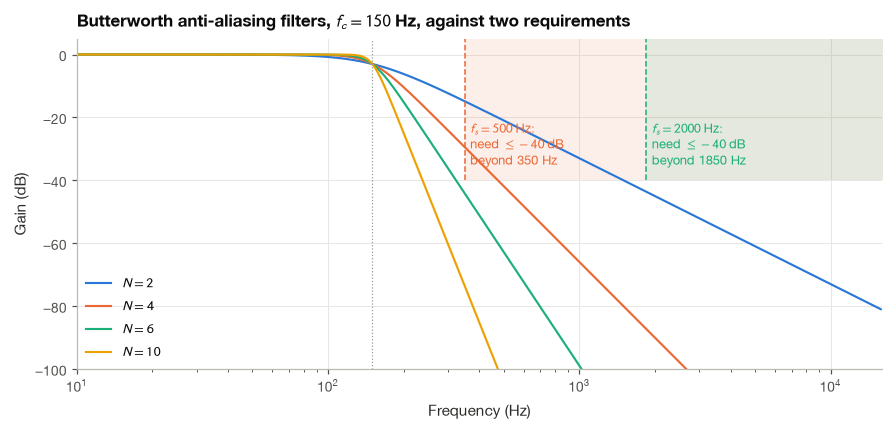

In [15]:
f = np.logspace(1, 4.2, 800)
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, N in enumerate((2, 4, 6, 10)):
    ax.semilogx(f, -10 * np.log10(1 + (f / f_c) ** (2 * N)), color=C[k], label=f"$N = {N}$")
for fs_adc, color in [(500, C[1]), (2000, C[2])]:
    f_stop = fs_adc - f_c
    ax.fill_between([f_stop, 2e4], -40, 5, color=color, alpha=0.10, lw=0)
    ax.plot([f_stop, f_stop], [-40, 5], color=color, lw=1, ls="--")
    ax.text(f_stop * 1.05, -36, f"$f_s = {fs_adc}$ Hz:\nneed $\\leq -40$ dB\nbeyond {f_stop:.0f} Hz",
            fontsize=8.5, color=color, va="bottom")
ax.axvline(f_c, color="0.6", lw=0.8, ls=":")
ax.set(xlabel="Frequency (Hz)", ylabel="Gain (dB)", ylim=(-100, 5), xlim=(10, 1.6e4),
       title="Butterworth anti-aliasing filters, $f_c = 150$ Hz, against two requirements")
ax.legend(loc="lower left")
plt.show()

Raising the sampling rate moves the stopband edge away from the passband, and the required order collapses: at 500 Hz the relaxed 40 dB requirement needs a sixth-order filter, at 2 kHz a second-order one suffices, and above that the order barely changes. The faster rate has a cost in data volume, but that is easily recovered digitally, as the next subsection shows.

Two practical remarks complete the picture. First, the Butterworth filter is not the only choice: Chebyshev and elliptic filters are steeper for the same order but distort the passband, and Bessel filters roll off slowly but delay all frequencies almost equally, which preserves the shape of the QRS complex (Section 15.1, [Section 13.2](../ch13_filter_fundamentals/index.md)). Second, the cutoff of a real filter should sit a little above the passband edge if the passband must be flat; I set $f_c = f_p$ above only to keep the arithmetic simple.

(sec-6-2-5)=
## 6.2.5 Oversampling and Digital Decimation

The table suggests a strategy that almost every modern biopotential front end uses. Sample much faster than the final rate, $f_s' = M f_s$, so that a cheap, low-order analog filter is enough to prevent aliasing at the fast rate. Then, in the digital domain, low-pass filter the signal down to the final band with a sharp digital filter, and keep only every $M$-th sample. The combination of digital low-pass filtering and downsampling is called **decimation** by $M$, and the factor $M$ (or the ratio $f_s'/(2B)$) is the **oversampling ratio**.

Why does it work? At the fast rate the analog filter only has to suppress content above $f_s' - f_p$ (equation 9.9 at the fast rate), which is far from the passband. The digital filter then removes everything between the passband edge and the final folding frequency $f_s/2$. When we finally discard samples, the signal is already band-limited below $f_s/2$, so by [Section 6.1](01_sampling_theorem.ipynb) the slower rate represents it without loss. Digital filters are ideal for this second step: they can be made extremely steep with exactly linear phase, they never drift with temperature or component tolerance, and every channel gets an identical copy. Oversampling has a second benefit, a reduction of quantization noise, which we quantify in Section 9.4.

### Building a decimator from scratch

A decimator needs only two ingredients: a linear-phase FIR low-pass filter with cutoff at the new Nyquist frequency, and a downsampler. We design the filter with `scipy.signal.firwin` (the window method of [Section 14.2](../ch14_fir/index.md)), convolve, remove the filter's delay of $(L-1)/2$ samples so that output and input stay aligned, and keep every $M$-th sample. With $L = 20M + 1$ taps and a Hamming window this is exactly the recipe that `scipy.signal.decimate` uses, so the two should agree to rounding error on the EMG of Section 6.2.3.

In [16]:
def decimate_fir(x, M, numtaps=None):
    """Low-pass filter x with a linear-phase FIR (cutoff at the new Nyquist) and keep every M-th sample."""
    numtaps = numtaps or 20 * M + 1
    h = signal.firwin(numtaps, 1 / M, window="hamming")    # cutoff as a fraction of the old Nyquist
    delay = (numtaps - 1) // 2
    y = np.convolve(x, h)[delay: delay + x.size]            # zero-phase alignment
    return y[::M], h


emg_ours, h_dec = decimate_fir(emg, M)
print(f"Max difference from scipy.signal.decimate: {np.max(np.abs(emg_ours - emg_dec)):.1e} mV")

w, H = signal.freqz(h_dec, worN=[100, 200, 225, 250, 275, 300, 400], fs=fs_emg)
print(pd.DataFrame({"frequency (Hz)": w, "gain (dB)": 20 * np.log10(np.abs(H))}).round(1).to_string(index=False))

Max difference from scipy.signal.decimate: 4.4e-16 mV
 frequency (Hz)  gain (dB)
          100.0       -0.0
          200.0        0.0
          225.0       -0.7
          250.0       -6.0
          275.0      -22.1
          300.0      -52.8
          400.0      -61.5


The printed gains reveal a design compromise. The filter is flat to 200 Hz and attenuates by more than 50 dB from 300 Hz upward, but its transition band straddles the new folding frequency of 250 Hz, with only 6 dB of attenuation exactly at 250 Hz. Content between 250 and 300 Hz is therefore only partly removed and folds into 200–250 Hz. In practice I treat the top 10–20% of the band after `decimate` as unreliable, or I design the filter with its stopband starting at $f_s/2$, which costs more taps. Because the filter output is needed only at every $M$-th instant, an efficient implementation computes just those outputs, reducing the work by a factor of $M$; this is what the polyphase structure inside `scipy.signal.resample_poly` does (Section 9.3).

(sec-6-2-6)=
## 6.2.6 Case Study: Power-Line Harmonics in a Wearable ECG

We now return to the ward and the 8 Hz ripple of the introduction, and I want to solve it with the tools above. The goal is a single-lead ECG for rhythm monitoring, stored at $f_s = 128$ Hz with a band of interest of 0.5–40 Hz. The interference is mains pickup at 60 Hz with harmonics, as produced by nonlinear loads (switching power supplies, LED drivers, fluorescent lighting) on the same circuit. We compare three acquisition chains:

- **A**: sample at 128 Hz with no anti-aliasing filter;
- **B**: a second-order Butterworth analog filter with $f_c = 40$ Hz, then sample at 128 Hz;
- **C**: a second-order Butterworth analog filter with $f_c = 200$ Hz, sample at $8 \times 128 = 1024$ Hz, then decimate digitally by 8.

### Step 1: Build a realistic analog input

The cardiac part is real: lead MLII of MIT-BIH record 100 {cite:p}`moody2001,goldberger2000`. Its content above about 100 Hz was removed when the database was created, so it can be brought to any of our rates by proper resampling (`resample_poly`, Section 9.3) without introducing aliasing of its own. The interference is simulated, because it consists of pure sinusoids whose value at any instant we can compute exactly. The amplitudes below are my assumptions, chosen to be typical of a poorly shielded wearable with dry electrodes: 200 µV at 60 Hz, a few tens of µV in the harmonics, with odd harmonics stronger than even ones as is usual for mains distortion. Phases are random.

In [17]:
fs_ecg = 360
ecg_360 = wfdb.rdrecord("../data/mitdb/100", channels=[0], sampto=fs_ecg * 60).p_signal[:, 0]

mains = pd.DataFrame({"frequency (Hz)": [60.0, 120.0, 180.0, 240.0, 300.0],
                      "amplitude (uV)": [200.0, 50.0, 100.0, 30.0, 60.0]})
mains_phase = rng.uniform(0, 2 * np.pi, len(mains))


def mains_interference(t, H=None):
    """Mains harmonics (mV) at times t, optionally through an analog filter with response H(f)."""
    y = np.zeros_like(t)
    for (f, amp_uV), ph in zip(mains[["frequency (Hz)", "amplitude (uV)"]].to_numpy(), mains_phase):
        g = 1.0 if H is None else H(f)
        y += 1e-3 * amp_uV * np.abs(g) * np.cos(2 * np.pi * f * t + ph + np.angle(g))
    return y


def butterworth_analog(N, fc):
    """Frequency response H(f) of an analog Butterworth low-pass filter."""
    b, a = signal.butter(N, 2 * np.pi * fc, analog=True)
    return lambda f: signal.freqs(b, a, [2 * np.pi * f])[1][0]


mains["alias at 128 Hz (Hz)"] = apparent_frequency(mains["frequency (Hz)"], 128.0)
print(mains.to_string(index=False))

 frequency (Hz)  amplitude (uV)  alias at 128 Hz (Hz)
           60.0           200.0                  60.0
          120.0            50.0                   8.0
          180.0           100.0                  52.0
          240.0            30.0                  16.0
          300.0            60.0                  44.0


The last column applies equation [(6.8)](#eq-6-8) in advance. Two harmonics fold into the 0.5–40 Hz band, 120 Hz to 8 Hz and 240 Hz to 16 Hz; the others land between 40 and 64 Hz.

### Step 2: Simulate the three acquisition chains

Each chain is a linear system, so we can pass the ECG and the interference through it separately and add the results, which also lets us measure the interference that survives without the ECG getting in the way. For chains A and B the interference is evaluated directly at the 128 Hz sampling instants, after multiplying each harmonic by the analog filter's complex gain. For the ECG in chain B the analog filter is approximated by its digital equivalent at 360 Hz before resampling; this is accurate because the record contains nothing above 100 Hz. In chain C the 200 Hz analog filter changes the ECG band by less than 0.01 dB, so we omit it for the ECG.

In [18]:
fs_out, M_os = 128, 8
ecg_128 = signal.resample_poly(ecg_360, 16, 45)              # 360 Hz * 16/45 = 128 Hz
t_128 = np.arange(ecg_128.size) / fs_out

b40, a40 = signal.butter(2, 40, fs=fs_ecg)
ecg_128_B = signal.resample_poly(signal.lfilter(b40, a40, ecg_360), 16, 45)

noise_A = mains_interference(t_128)
noise_B = mains_interference(t_128, butterworth_analog(2, 40))

ecg_1024 = signal.resample_poly(ecg_360, 128, 45)            # 360 Hz * 128/45 = 1024 Hz
t_1024 = np.arange(ecg_1024.size) / (fs_out * M_os)
noise_C_fast = mains_interference(t_1024, butterworth_analog(2, 200))
noise_C, _ = decimate_fir(noise_C_fast, M_os)
ecg_C, _ = decimate_fir(ecg_1024, M_os)

chains = {"A: no filter": (ecg_128, noise_A), "B: analog 2nd order, 40 Hz": (ecg_128_B, noise_B),
          "C: 1024 Hz + digital decimation": (ecg_C, noise_C)}
print({name: x.size for name, (x, _) in chains.items()})

{'A: no filter': 7680, 'B: analog 2nd order, 40 Hz': 7680, 'C: 1024 Hz + digital decimation': 7680}


### Step 3: Look at the result of the naive design

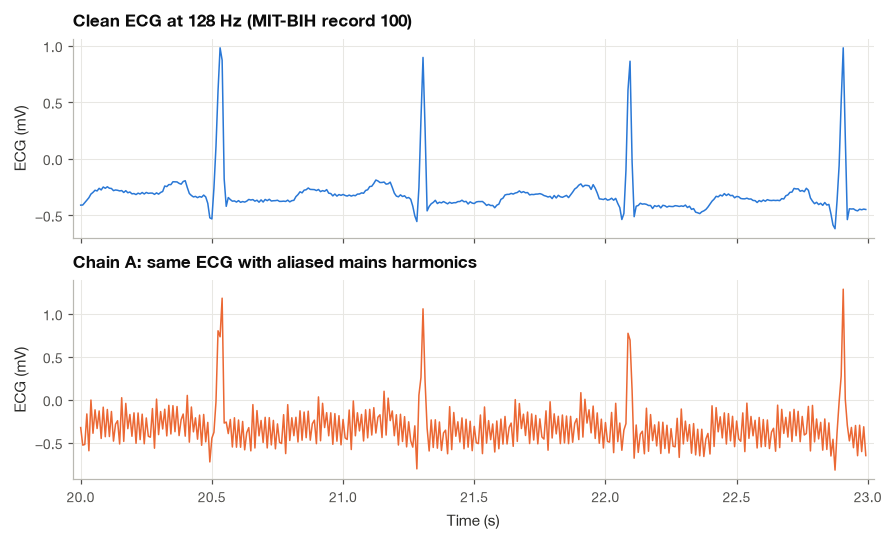

In [19]:
show = (t_128 >= 20) & (t_128 < 23)
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
axes[0].plot(t_128[show], ecg_128[show], color=C[0], lw=1)
axes[0].set(ylabel="ECG (mV)", title="Clean ECG at 128 Hz (MIT-BIH record 100)")
axes[1].plot(t_128[show], ecg_128[show] + noise_A[show], color=C[1], lw=1)
axes[1].set(xlabel="Time (s)", ylabel="ECG (mV)", title="Chain A: same ECG with aliased mains harmonics")
plt.show()

The trace in chain A is visibly corrupted between beats by a fast irregular ripple. It is the sum of the 60 Hz fundamental and four aliases at 8, 16, 44 and 52 Hz, which beat against each other.

### Step 4: Compare the spectra

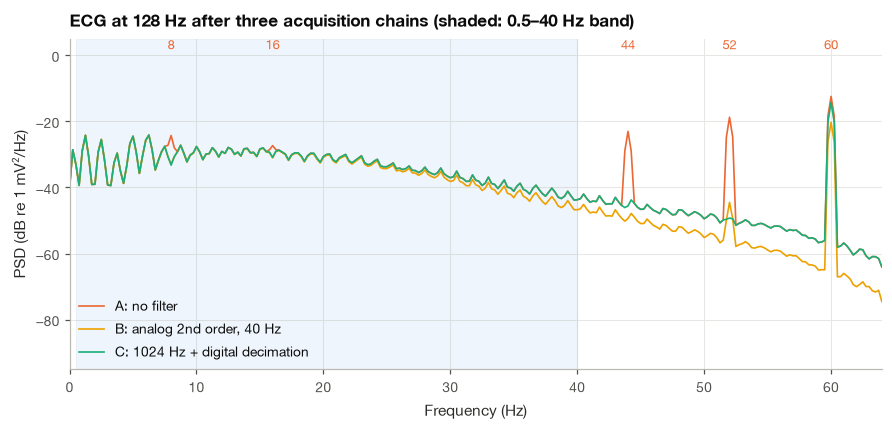

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (name, (ecg_part, noise_part)) in enumerate(chains.items()):
    f_w, P_w = signal.welch(ecg_part + noise_part, fs_out, nperseg=4 * fs_out)
    ax.plot(f_w, 10 * np.log10(P_w), color=C[[1, 3, 2][k]], lw=1.1, label=name)
ax.axvspan(0.5, 40, color=C[0], alpha=0.07)
for fa in mains["alias at 128 Hz (Hz)"]:
    ax.annotate(f"{fa:.0f}", (fa, 0), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5, color=C[1])
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV$^2$/Hz)", xlim=(0, 64), ylim=(-95, 5),
       title="ECG at 128 Hz after three acquisition chains (shaded: 0.5–40 Hz band)")
ax.legend(loc="lower left")
plt.show()

In chain A the aliases stand out as sharp lines at 8, 16, 44 and 52 Hz, labeled at the top, next to the genuine 60 Hz line. The 8 and 16 Hz lines sit on top of the ECG's own spectrum, in the band that QRS detectors rely on. Chain B suppresses them but also attenuates the ECG above about 30 Hz, because its gentle second-order roll-off had to start inside the band. Chain C removes every alias to below the floor of the plot while leaving the band untouched; only the 60 Hz fundamental, which never aliased, remains, waiting for a notch filter (Section 15.4).

### Step 5: Measure the surviving aliases

To put numbers on the comparison we measure the amplitude of the interference at each alias frequency with the phasor estimator of equation [(2.3)](../ch02_math_toolkit/01_complex_numbers.ipynb#eq-2-3) in [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb), applied to the interference that passed through each chain. Using exactly 58 s of data (an integer number of cycles of every component) keeps the estimates free of leakage, a topic of Section 10.4.

In [21]:
def phasor_amplitude(x, f0, fs):
    """Amplitude of the f0 component of x, equation (2.3)."""
    n = np.arange(x.size)
    return np.abs(2 / x.size * np.sum(x * np.exp(-2j * np.pi * f0 * n / fs)))


segment = slice(fs_out, fs_out * 59)                         # skip filter edges, keep 58 s
rows = []
for name, (_, noise_part) in chains.items():
    row = {"chain": name}
    for fa in (8, 16, 44, 52, 60):
        row[f"{fa} Hz (uV)"] = 1e3 * phasor_amplitude(noise_part[segment], fa, fs_out)
    rows.append(row)
print(pd.DataFrame(rows).round(2).to_string(index=False))

                          chain  8 Hz (uV)  16 Hz (uV)  44 Hz (uV)  52 Hz (uV)  60 Hz (uV)
                   A: no filter      50.00       30.00       60.00      100.00      200.00
     B: analog 2nd order, 40 Hz       5.52        0.83        1.07        4.93       81.23
C: 1024 Hz + digital decimation       0.02        0.00        0.00        0.02      160.67


Without a filter the in-band aliases have their full amplitudes, 50 µV at 8 Hz and 30 µV at 16 Hz, comparable to a P wave. The 40 Hz analog filter reduces them about tenfold and thirtyfold, to 5.5 µV and 0.8 µV, exactly the Butterworth gains $|H(120)| = 0.11$ and $|H(240)| = 0.028$ predicted by the formula in Section 6.2.4. Oversampling with digital decimation drives them below 0.05 µV, more than three orders of magnitude below chain A, with an analog filter whose cutoff of 200 Hz is far outside the band and whose tolerances therefore hardly matter. The 60 Hz component is reduced in chains B and C only by the edges of their low-pass responses; it was never an alias, and it is the one component a 60 Hz notch can still remove.

This is the general lesson of the section. Aliasing must be prevented before the converter, because afterwards it is indistinguishable from signal. A steep analog filter at the final rate is expensive and imperfect; oversampling relaxes the analog requirement so much that a simple filter suffices, and the sharp filtering is done digitally where it is cheap and exact.

## Summary

A sinusoid at frequency $f$ and one at $f + kf_s$ produce identical samples, and one at $kf_s - f$ produces the same samples with reversed phase. After sampling, every frequency therefore appears at its apparent frequency $f_a = |f - f_s\operatorname{round}(f/f_s)|$ in the range $[0, f_s/2]$, which amounts to folding the frequency axis like an accordion at multiples of the folding frequency $f_s/2$. With a continuous spectrum, the folded strips pile on top of the genuine band: naive downsampling of a needle EMG by 8 inflated the 20–200 Hz power by about 80% and shifted its mean frequency by about 8 Hz, while filtering before downsampling preserved the spectrum.

Aliasing is prevented by an analog anti-aliasing filter in front of the converter. Its stopband must begin at $f_s/2$ to keep the whole digital band clean, or at $f_s - f_p$ to protect only the band of interest, and equation [(6.10)](#eq-6-10) gives the Butterworth order needed for a given attenuation. At sampling rates just above twice the band, the required orders are impractically high; oversampling followed by a sharp digital decimation filter lets a second-order analog filter do the job, as the wearable-ECG case study showed. Section 9.3 develops the digital side of rate conversion further, Section 9.4 shows that oversampling also lowers quantization noise, and [Section 11.2](../ch17_ecg/index.md) applies these ideas to a complete ECG front end.

## Exercises

1. An EEG system samples at 256 Hz. At what apparent frequencies do interference components at 50, 100, 150, 200 and 250 Hz appear? Which of them fall in the beta band (13–30 Hz)?
2. Show from equation [(6.8)](#eq-6-8) that a component at exactly $f = f_s$ appears at 0 Hz, and explain why a PPG sensor sampling at 100 Hz under lighting that flickers at 100 Hz (twice the mains frequency in a 50 Hz country) can show a slowly drifting baseline instead of a ripple. What happens if the flicker frequency is 100.2 Hz?
3. Using equation [(6.10)](#eq-6-10), find the Butterworth order needed for 60 dB of attenuation in a surface EMG system with a passband edge of 500 Hz sampled at 2 kHz, under both the strict and the relaxed specifications. Verify with `scipy.signal.buttord`. By how much would you need to raise the sampling rate to bring the relaxed order down to 2?
4. Repeat the needle EMG experiment of [Section 6.2.3](#sec-6-2-3) with the healthy recording (`emg_healthy`) and with downsampling factors $M = 4, 8, 16$. Plot the error in the 20–200 Hz mean frequency against $M$ for naive and filtered downsampling, and explain the trend using the fraction of power above the new Nyquist frequency.
5. In the case study, replace the second-order analog filter of chain B with a fourth-order Butterworth at 40 Hz. Predict the surviving amplitudes at 8 and 16 Hz with the Butterworth formula, then confirm them with the simulation. What does the fourth-order filter do to the ECG between 25 and 40 Hz?
6. (Challenge) Real mains interference also contains harmonics up to the 15th and beyond. Extend the interference model to harmonics up to 900 Hz with amplitudes decaying as $1/k$, and find the smallest oversampling factor $M$ (with the second-order 200 Hz analog filter of chain C) that keeps every in-band alias below 1 µV. Explain your result with equation [(6.9)](#eq-6-9).

## Further Reading

Aliasing and decimation are treated carefully in {cite:t}`oppenheim2010` (Chapter 3), including the frequency-domain description of downsampling. {cite:t}`lyons2010` gives an intuitive account of folding and of the practical design of decimation filters, and {cite:t}`smith1997` (Chapter 3) discusses anti-aliasing filters and the choice between Butterworth, Chebyshev and Bessel responses from a hardware point of view. For the instrumentation side of biopotential acquisition, including filter placement in the analog front end, see {cite:t}`webster2010`.